# Детекция ArUco маркеров

Используются классы проекта:

- `PhotoArucoDetector` — обработка одиночного фото
- `VideoArucoDetector` — покадровая обработка видео
- `ArucoDetect` — общий детектор: матрица камеры, `solvePnP`, отрисовка

Запускать из корня проекта (`algo-photogrammetry`), ядро — `.venv`. Окна OpenCV не используются, результат выводится через matplotlib.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import settings
from src.detectors import PhotoArucoDetector, VideoArucoDetector
from src.model_config import ModelConfig


def show_image(image: np.ndarray, title: str = "Результат") -> None:
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


In [2]:
MARKER_SIZE = 0.2

MODEL_CAMERA = "cam1"
RUN_ID = "20261117_143842_full"  # <-- выбрать нужный прогон
OUTPUT_ROOT = settings.root.parent / "output" / "runs"
RUN_DIR = OUTPUT_ROOT / RUN_ID

MODEL_ROOT = settings.root.parent / "model-photogrammetry"
MODEL_VIDEO_PATH = RUN_DIR / "videos" / f"{MODEL_CAMERA}.mp4"

PHOTO_PATH = settings.input_photo / "test_photo.png"
PHOTO_OUTPUT_PATH = settings.output_photo / "test_result.jpg"

VIDEO_PATH = MODEL_VIDEO_PATH
VIDEO_OUTPUT_PATH = RUN_DIR / "detection" / f"{MODEL_CAMERA}.mp4"


## Генерация ArUco-меток


In [3]:
# from src.utils import generate_aruco_markers

# generated = generate_aruco_markers(count=6, marker_type="4x4")
# print(f"Сгенерировано меток: {len(generated)} в {settings.aruco_markers}")
# for path in generated:
#     print(path.name)


## Фото


Найдено маркеров: 3
ID: [1, 2, 0]
Маркер ID=1: tvec=[0.426 0.189 2.132], центр в координатах камеры=[0.426 0.189 2.132]
Маркер ID=2: tvec=[-0.427  0.224  2.106], центр в координатах камеры=[-0.427  0.224  2.106]
Маркер ID=0: tvec=[-0.03  -0.536  2.177], центр в координатах камеры=[-0.03  -0.536  2.177]
Маркеры найдены на изображении test_photo.png: True


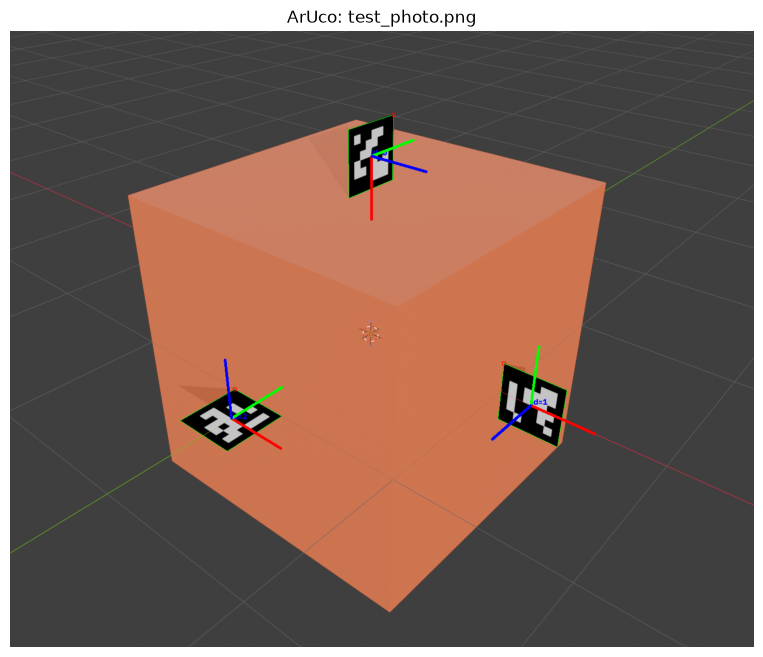

In [4]:
import os

with PhotoArucoDetector(marker_size=MARKER_SIZE) as detector:
    photo_results = {}
    for photo_path in sorted(settings.input_photo.iterdir()):
        output_path = settings.output_photo / photo_path.name
        photo_results[photo_path.name] = detector.process(
            photo_path,
            output_path,
            show=False,
            save=True,
        )

for name, result in photo_results.items():
    print(f"Маркеры найдены на изображении {name}: {result.found}")
    show_image(result.image, f"ArUco: {name}")


## Видео


In [5]:
model = ModelConfig.from_json(RUN_DIR / "config" / "scene.json")
model.validate_video(MODEL_CAMERA, VIDEO_PATH)

with VideoArucoDetector(
    **model.detector_kwargs(MODEL_CAMERA),
    save_measurements=True,
) as detector:
    for _ in detector.process(VIDEO_PATH, VIDEO_OUTPUT_PATH, show=False):
        pass

stats_path = VIDEO_OUTPUT_PATH.with_suffix(".csv")
print(f"Видео и статистика сохранены в: {VIDEO_OUTPUT_PATH.parent}")
print(pd.read_csv(stats_path, sep=";").to_string(index=False))

angles_path = (
    VIDEO_OUTPUT_PATH.parent / "measurements" / MODEL_CAMERA
    / "rotor_angles_measured.csv"
)
print(f"Rotor angles: {angles_path}")


Кадр 1/301: ID [5, 1, 2, 0, 3]
Кадр 2/301: ID [5, 1, 2, 0, 3]
Кадр 3/301: ID [5, 1, 2, 0, 3]
Кадр 4/301: ID [5, 1, 0, 3]
Кадр 5/301: ID [5, 1, 2, 0, 3]
Кадр 6/301: ID [5, 1, 0, 2, 3]
Кадр 7/301: ID [5, 1, 2, 0, 3]
Кадр 8/301: ID [5, 1, 0, 2, 3]
Кадр 9/301: ID [5, 1, 0, 2, 3]
Кадр 10/301: ID [5, 1, 0, 2, 3]
Кадр 11/301: ID [5, 1, 2, 0, 3]
Кадр 12/301: ID [5, 1, 0, 2, 3]
Кадр 13/301: ID [5, 1, 0, 2, 3]
Кадр 14/301: ID [5, 1, 0, 2, 3]
Кадр 15/301: ID [5, 1, 0, 2, 3]
Кадр 16/301: ID [5, 1, 0, 2, 3]
Кадр 17/301: ID [5, 1, 0, 2, 3]
Кадр 18/301: ID [5, 1, 0, 2, 3]
Кадр 19/301: ID [5, 1, 0, 2, 3]
Кадр 20/301: ID [5, 1, 0, 2, 3]
Кадр 21/301: ID [5, 1, 0, 2, 3]
Кадр 22/301: ID [5, 1, 0, 2, 3]
Кадр 23/301: ID [5, 1, 0, 2, 3]
Кадр 24/301: ID [5, 1, 0, 2, 3]
Кадр 25/301: ID [5, 1, 0, 2, 3]
Кадр 26/301: ID [5, 1, 0, 2, 3]
Кадр 27/301: ID [5, 1, 0, 2, 3]
Кадр 28/301: ID [5, 1, 0, 2, 3]
Кадр 29/301: ID [5, 1, 0, 2, 3]
Кадр 30/301: ID [5, 1, 0, 2, 3]
Кадр 31/301: ID [5, 1, 0, 2, 3]
Кадр 32/301: ID [5, 

## Сравнение углов

Результаты сохраняются в `output/comparison/<camera>/`.


Сравнение углов, cam1
Углы
  кадров: 301
  phi: mean_abs=1.8449 deg, median_abs=1.7312 deg, rmse=2.2358 deg, max_abs=6.8421 deg
  theta: mean_abs=1.3865 deg, median_abs=1.4385 deg, rmse=1.5516 deg, max_abs=3.5135 deg

Результаты: D:\My\Projects\diplom\photogram\output\runs\20261117_143842_full\comparison\cam1


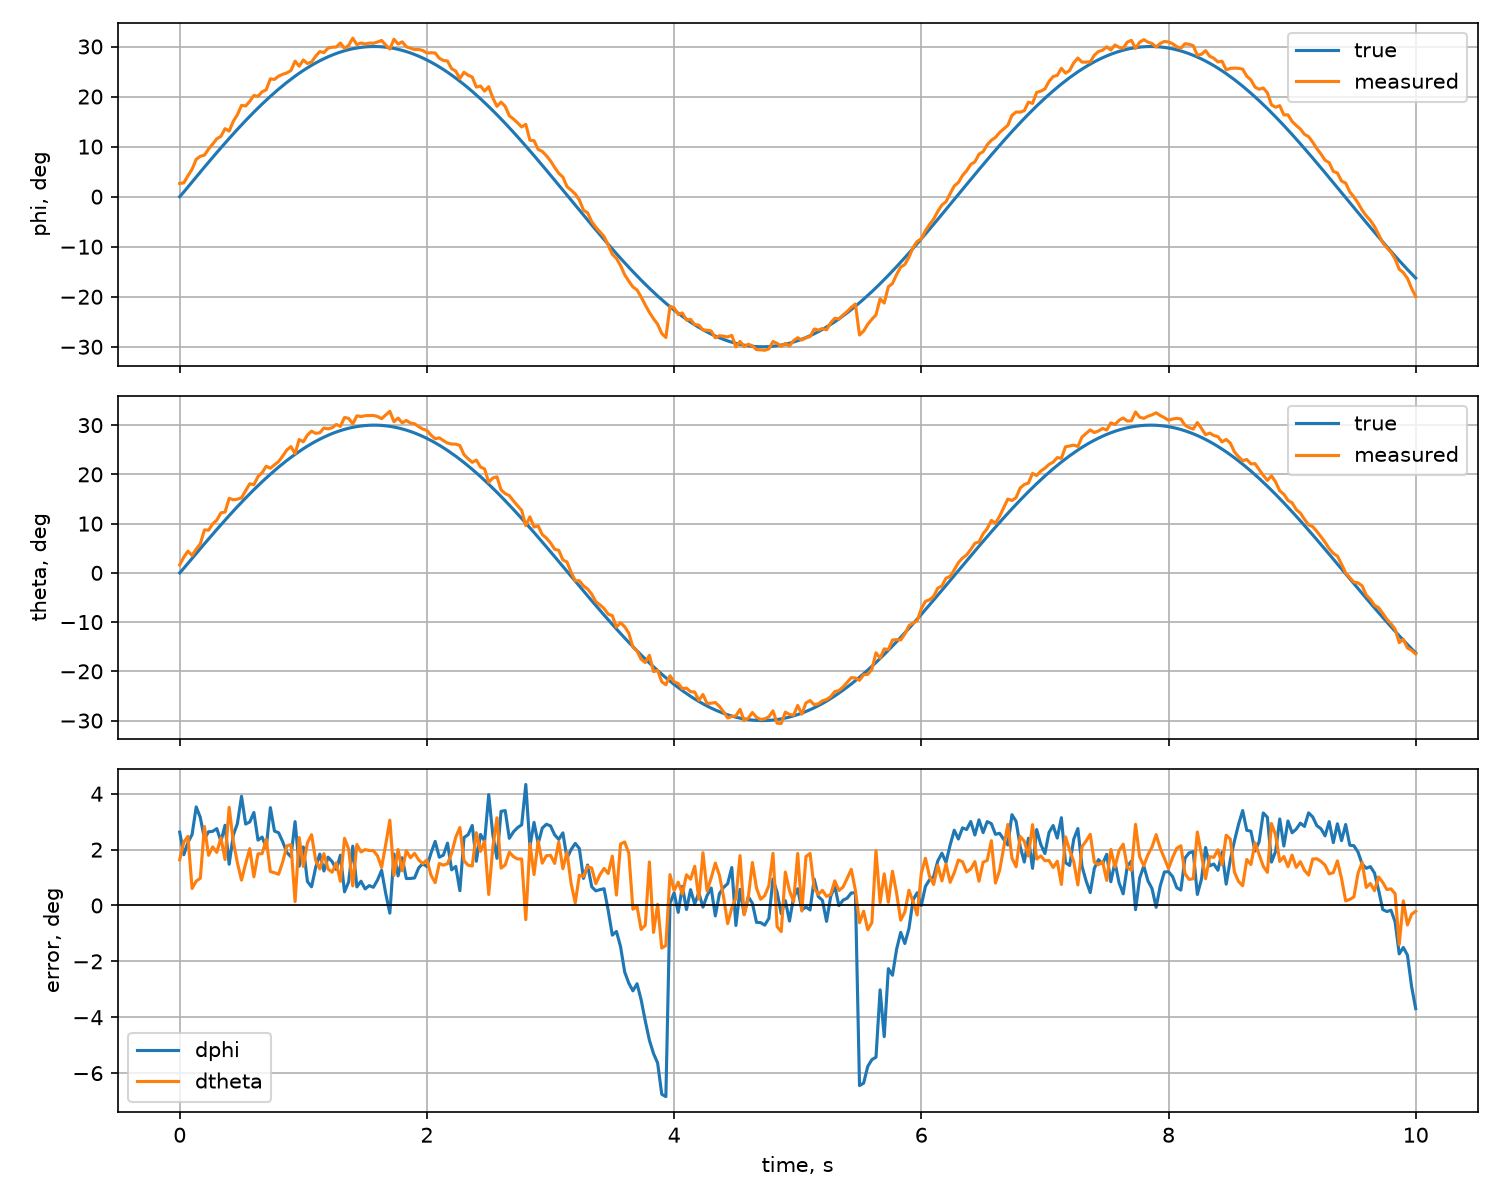

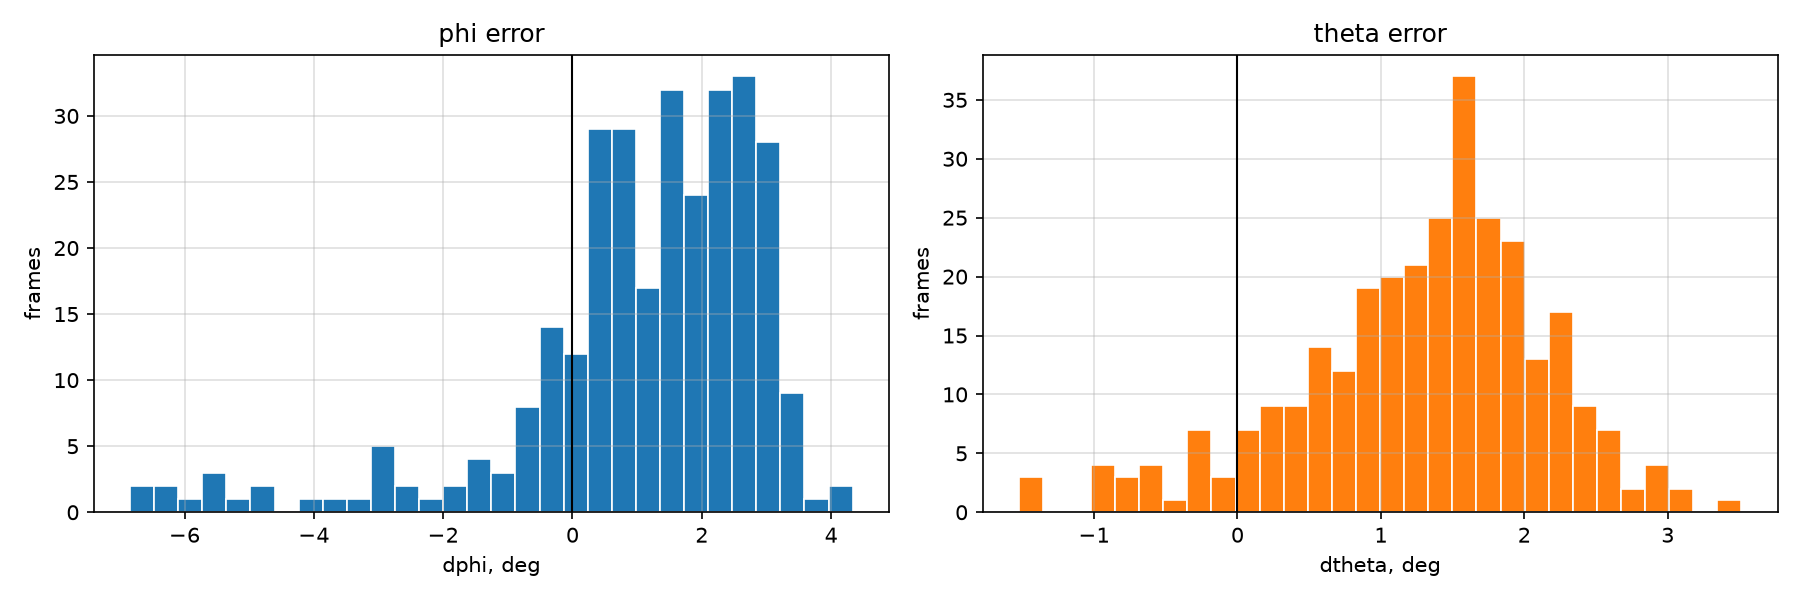

In [6]:
from IPython.display import Image, display
from scripts.compare_results import compare

comparison_dir = compare(
    camera=MODEL_CAMERA,
    true_dir=RUN_DIR / "ground_truth",
    measured_dir=RUN_DIR / "detection" / "measurements" / MODEL_CAMERA,
    output_dir=RUN_DIR / "comparison" / MODEL_CAMERA,
)

display(Image(filename=str(comparison_dir / "angles.png")))
display(Image(filename=str(comparison_dir / "angle_errors_hist.png")))
